# Statistical Hypothesis Testing Using the Iris Dataset
## 1. Objective and hypotheses
**Research question:** Do Iris Setosa and Iris Versicolor have different population mean sepal lengths?

- H₀: μ_setosa = μ_versicolor.
- H₁: μ_setosa ≠ μ_versicolor.
- Significance level: α = 0.05, selected before testing.
- Two-sided test; the unit of observation is a flower.

Source: [UCI Iris dataset](https://archive.ics.uci.edu/dataset/53/iris), loaded through scikit-learn. The original dataset contains 150 real flower measurements. This analysis focuses on two prespecified species (100 observations).

## 2. Import libraries and load dataset

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_iris
from IPython.display import display
alpha = 0.05
iris = load_iris(as_frame=True)
df = iris.data.copy()
df['species'] = iris.target.map(dict(enumerate(iris.target_names)))
display(df.head())
print('Dataset shape:', df.shape)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)


## 3. Check data quality
Check missing values and identical records. Identical measurements are not necessarily duplicate flowers; retain them because no specimen identifiers establish duplication.

In [2]:
display(df.isna().sum())
print('Identical rows:', df.duplicated().sum())
print('Species counts:')
print(df['species'].value_counts())
subset = df[df['species'].isin(['setosa', 'versicolor'])].copy()
print('Missing analysis values:', subset[['species','sepal length (cm)']].isna().sum().sum())
assert not subset[['species','sepal length (cm)']].isna().any().any()
a = subset.loc[subset.species == 'setosa', 'sepal length (cm)'].to_numpy()
b = subset.loc[subset.species == 'versicolor', 'sepal length (cm)'].to_numpy()
display(subset.groupby('species')['sepal length (cm)'].describe())

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


Identical rows: 1
Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Missing analysis values: 0


,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
setosa,50.0,5.006,0.352490,4.3,4.8,5.0,5.2,5.8
versicolor,50.0,5.936,0.516171,4.9,5.6,5.9,6.3,7.0


## 4. Exploratory analysis
Visualize distributions and potential outliers. IQR flags are diagnostic, not automatic grounds for deletion.

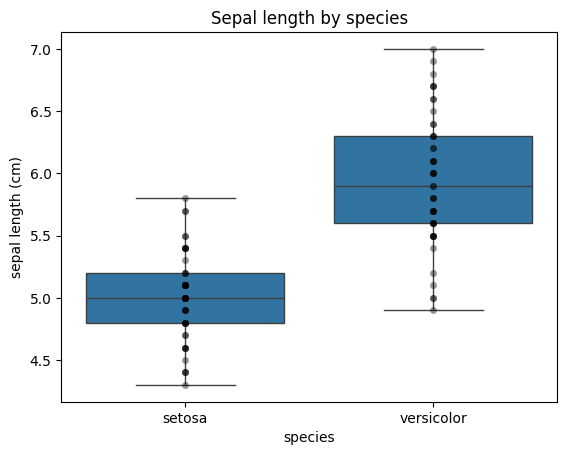

Setosa IQR flagged values: []
Versicolor IQR flagged values: []


In [3]:
sns.boxplot(data=subset, x='species', y='sepal length (cm)')
sns.stripplot(data=subset, x='species', y='sepal length (cm)', color='black', alpha=.4, jitter=False)
plt.title('Sepal length by species')
plt.show()
for name, values in [('Setosa', a), ('Versicolor', b)]:
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3-q1
    print(name, 'IQR flagged values:', values[(values < q1-1.5*iqr) | (values > q3+1.5*iqr)])

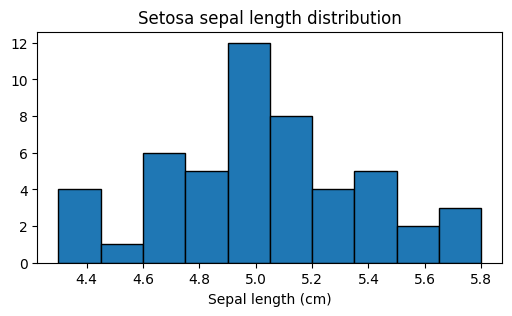

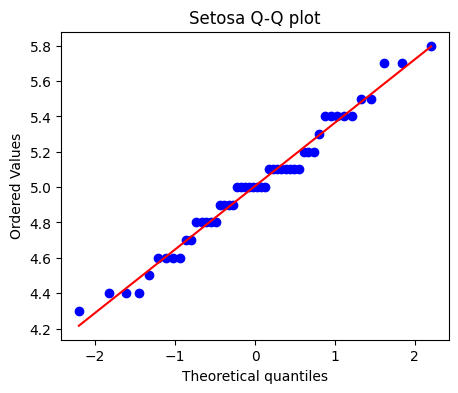

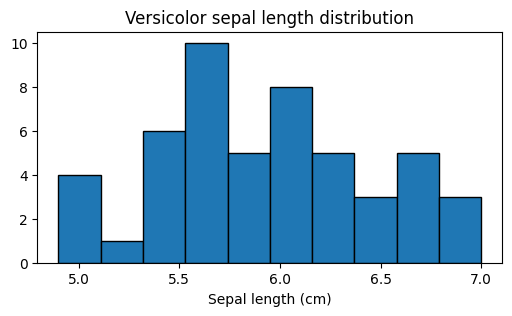

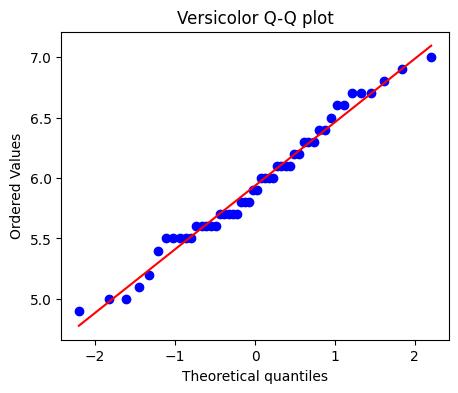

In [4]:
for name, values in [('Setosa', a), ('Versicolor', b)]:
    plt.figure(figsize=(6,3))
    plt.hist(values, bins=10, edgecolor="black")
    plt.title(name + ' sepal length distribution')
    plt.xlabel('Sepal length (cm)')
    plt.show()
    plt.figure(figsize=(5,4))
    stats.probplot(values, dist='norm', plot=plt)
    plt.title(name + ' Q-Q plot')
    plt.show()

## 5. Test selection and assumption checks
Welch’s independent t-test compares two population means for a continuous measurement and does not require equal variances. Independence is assumed because the records represent separate flowers; the dataset does not establish random sampling or rule out clustering. Shapiro–Wilk checks normality and Levene’s median-centered test checks equal variances. A non-significant normality result does not prove normality.

In [5]:
for name, values in [('Setosa', a), ('Versicolor', b)]:
    w, p = stats.shapiro(values)
    print(f'{name}: Shapiro W={w:.4f}, p={p:.6f}')
    print('Reject normality' if p < alpha else 'No evidence against normality at alpha=0.05')
lv = stats.levene(a, b, center='median')
print(f'Levene statistic={lv.statistic:.4f}, p={lv.pvalue:.6f}')
print('Evidence of unequal variances' if lv.pvalue < alpha else 'No evidence of unequal variances')

Setosa: Shapiro W=0.9777, p=0.459513
No evidence against normality at alpha=0.05
Versicolor: Shapiro W=0.9778, p=0.464737
No evidence against normality at alpha=0.05
Levene statistic=8.1727, p=0.005196
Evidence of unequal variances


Both normality tests fail to reject normality. The variance test rejects equality, supporting Welch rather than the pooled-variance t-test. With 50 observations per group, Welch is also reasonably robust to moderate non-normality. No measurements are removed without evidence of error.

## 6. Perform the hypothesis test

In [6]:
result = stats.ttest_ind(a, b, equal_var=False, alternative='two-sided')
print(f'Welch t-statistic: {result.statistic:.6f}')
print(f'Degrees of freedom: {result.df:.4f}')
print(f'p-value: {result.pvalue:.8e}')
print('Decision:', 'Reject H0' if result.pvalue < alpha else 'Fail to reject H0')

Welch t-statistic: -10.520986
Degrees of freedom: 86.5380
p-value: 3.74674261e-17
Decision: Reject H0


## 7. Practical significance and confidence interval
Report the raw difference (Versicolor minus Setosa), its 95% Welch confidence interval and descriptive Cohen’s d using pooled sample standard deviation. The latter is a standardized descriptive effect, not an equal-variance assumption for the test. An illustrative practical threshold of 0.5 cm is used for discussion only; it is not a validated botanical threshold.

Setosa mean: 5.006 cm
Versicolor mean: 5.936 cm
Mean difference: 0.930 cm
95% confidence interval: [0.754, 1.106] cm
Cohen d (descriptive): 2.104


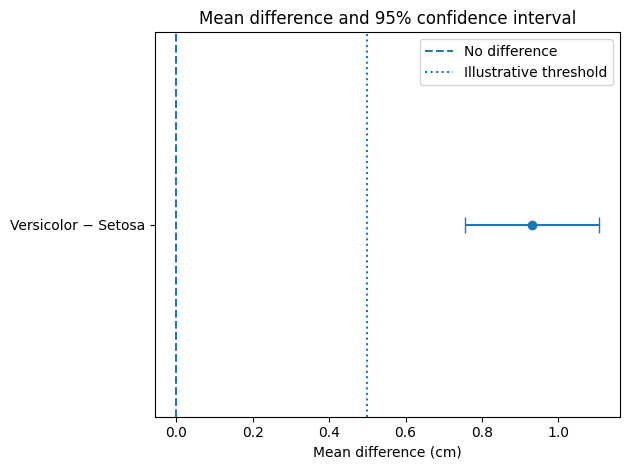

In [7]:
difference = b.mean() - a.mean()
se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
critical = stats.t.ppf(1-alpha/2, result.df)
lo, hi = difference-critical*se, difference+critical*se
pooled_sd = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
d = difference/pooled_sd
print(f'Setosa mean: {a.mean():.3f} cm')
print(f'Versicolor mean: {b.mean():.3f} cm')
print(f'Mean difference: {difference:.3f} cm')
print(f'95% confidence interval: [{lo:.3f}, {hi:.3f}] cm')
print(f'Cohen d (descriptive): {d:.3f}')
plt.errorbar(difference, 0, xerr=[[difference-lo],[hi-difference]], fmt='o', capsize=6)
plt.axvline(0, linestyle='--', label='No difference')
plt.axvline(.5, linestyle=':', label='Illustrative threshold')
plt.yticks([0], ['Versicolor − Setosa'])
plt.xlabel('Mean difference (cm)')
plt.title('Mean difference and 95% confidence interval')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Interpretation and limitations
The p-value is the probability, assuming equal population means and the test model, of obtaining a test statistic at least as extreme as the observed one. It is not the probability that the null hypothesis is true. The result indicates a difference in average sepal length, not that every Versicolor flower has a longer sepal than every Setosa flower. Observational data do not establish causation, and the sampling design limits generalization. Sepal length alone is not a validated classifier.

## 9. Generate written report for GitHub submission
The following cell builds a Markdown report directly from the computed results.

In [8]:
report = f"""# Statistical Hypothesis Testing: Iris Sepal Length

## Research question and hypotheses
Do Setosa and Versicolor flowers differ in average sepal length? H0: their population means are equal. H1: their population means differ. Alpha = {alpha} (two-sided).

## Dataset and method
The [UCI Iris dataset](https://archive.ics.uci.edu/dataset/53/iris) was loaded using scikit-learn. We analyzed {len(a)} Setosa and {len(b)} Versicolor flowers. There were no missing analysis values. Identical measurements were retained because they cannot be verified as duplicate specimens. IQR screening and box plots were used to inspect potential outliers; no records were removed. Welch's independent t-test was selected to compare two continuous-outcome group means without assuming equal variances.

## Assumptions
Shapiro–Wilk p-values were {stats.shapiro(a).pvalue:.4f} and {stats.shapiro(b).pvalue:.4f}; neither rejects normality. Levene's test gave p = {lv.pvalue:.6f}, indicating unequal variances. Independence is assumed for separate flower records but cannot be verified from the available sampling metadata. Histograms and Q-Q plots were also inspected.

## Results
| Metric | Value |
|---|---:|
| Setosa mean | {a.mean():.3f} cm |
| Versicolor mean | {b.mean():.3f} cm |
| Welch t-statistic (Setosa minus Versicolor) | {result.statistic:.6f} |
| Degrees of freedom | {result.df:.4f} |
| p-value | {result.pvalue:.8e} |
| Mean difference (Versicolor minus Setosa) | {difference:.3f} cm |
| 95% confidence interval | [{lo:.3f}, {hi:.3f}] cm |
| Descriptive Cohen's d | {d:.3f} |

## Statistical significance
The p-value is below 0.05, so we reject the null hypothesis. Under the null and test assumptions, a statistic this extreme or more extreme is very unlikely. This is not the probability that the null is true.

## Practical significance
Versicolor sepals are on average {difference:.3f} cm longer. The entire confidence interval is above an illustrative 0.5 cm threshold, and the standardized difference is large. This may be useful for distinguishing species, but the threshold is not a validated botanical standard and classification performance has not been tested.

## Conclusion and limitations
The data provide strong evidence that the two species have different average sepal lengths. The difference concerns group averages, not every individual flower. The observational dataset does not establish causality, and representativeness and independence cannot be fully verified. Further validation is needed before using sepal length for classification.

## Reproducibility
Run the accompanying Google Colab notebook from top to bottom using Python, pandas, NumPy, SciPy, seaborn, matplotlib and scikit-learn.
"""
from pathlib import Path
Path('README.md').write_text(report, encoding='utf-8')
print(report)

# Statistical Hypothesis Testing: Iris Sepal Length

## Research question and hypotheses
Do Setosa and Versicolor flowers differ in average sepal length? H0: their population means are equal. H1: their population means differ. Alpha = 0.05 (two-sided).

## Dataset and method
The [UCI Iris dataset](https://archive.ics.uci.edu/dataset/53/iris) was loaded using scikit-learn. We analyzed 50 Setosa and 50 Versicolor flowers. There were no missing analysis values. Identical measurements were retained because they cannot be verified as duplicate specimens. IQR screening and box plots were used to inspect potential outliers; no records were removed. Welch's independent t-test was selected to compare two continuous-outcome group means without assuming equal variances.

## Assumptions
Shapiro–Wilk p-values were 0.4595 and 0.4647; neither rejects normality. Levene's test gave p = 0.005196, indicating unequal variances. Independence is assumed for separate flower records but cannot be verified fro

## 10. Submission
Upload this notebook and the generated README.md to a GitHub repository. Submit the URL of the README.md file. In Colab you can retrieve the report using the Files panel.

References: [SciPy statistics](https://docs.scipy.org/doc/scipy/reference/stats.html), [UCI Iris](https://archive.ics.uci.edu/dataset/53/iris).